<a href="https://colab.research.google.com/github/mamkon/Architecture_and_Data_Audit/blob/main/MamkonMO_CIND820_Milestone4_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CIND 820 Milestone 4 — Final Analysis
## Chronic Disease Burden and Healthcare Access Equity Across Ontario Public Health Units

**Student:** Mamkon Mercy Oyeleke
**Student Number:** 501279489
**Course:** CIND 820 — Big Data Analytics Project
**Supervisor:** Professor Ceni Babaoglu
**Toronto Metropolitan University**

This notebook extends Milestone 3 with the full Milestone 4 analysis: inferential regression, predictive model comparison (Linear Regression, Random Forest, Gradient Boosting), chronological stability validation, champion model selection, and PHO–CIHI healthcare access integration for RQ3.

**Data files required in the working directory:**
- `PHO_Chronic_Disease_Inc_Prev_Snapshot_2014_2023.xlsx`
- `CIHI_Wait_Times_Priority_Procedures_2025.xlsx`


### Environment Setup and Data Paths

**Interpretation:** This cell imports necessary Python libraries like pandas for data manipulation, numpy for numerical operations, matplotlib and seaborn for plotting, and scikit-learn for machine learning models. It also defines file paths for the input data (`PHO_PATH`, `CIHI_PATH`) and an output directory (`OUTPUT_DIR`) where generated figures and tables will be saved. A `RANDOM_STATE` is set for reproducibility.

**Insights:** This initial setup is crucial for ensuring that the entire analysis can run smoothly. The choice of libraries indicates a comprehensive approach involving data loading, cleaning, statistical analysis, and machine learning.

**Case Study Relevance:** By defining paths for `PHO_Chronic_Disease_Inc_Prev_Snapshot_2014_2023.xlsx` and `CIHI_Wait_Times_Priority_Procedures_2025.xlsx`, this cell directly links to the core datasets of the chronic disease burden and healthcare access equity study. The output directory structure (`milestone4_outputs/tables`, `milestone4_outputs/figures`) demonstrates a commitment to organizing and preserving the analytical results for the final report.

**Relationship:** This cell lays the groundwork for all subsequent code cells. It must be executed first to ensure that all required libraries are imported and that file paths are correctly defined before any data loading or processing can occur.

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time, warnings
from pathlib import Path
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.base import clone

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
PHO_PATH = "PHO_Chronic_Disease_Inc_Prev_Snapshot_2014_2023.xlsx"
CIHI_PATH = "CIHI DATA wait_times_priority_procedures_2025.xlsx"
OUTPUT_DIR = Path("milestone4_outputs")
(OUTPUT_DIR / "tables").mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / "figures").mkdir(parents=True, exist_ok=True)
print("Environment ready.")

Environment ready.


## 1. Load and prepare PHO data

### PHO Data Loading and Initial Preparation

**Interpretation:** This cell loads the PHO chronic disease data, renames a column, and converts key columns (`Year`, `Rate`, `Population`) to numeric types. It then filters the data to focus on age-standardized rates for individual Public Health Units (PHUs) in Ontario, excluding regional rollups and suppressed data. A new `Log_Rate` column is created by applying a log-transformation (`np.log1p`) to the `Rate`.

**Insights:** The filtering process ensures that the analysis focuses on relevant, reliable data at the PHU level, which is critical for assessing regional health equity. The `Log_Rate` transformation is a standard practice in statistical modeling for count or rate data, as it often helps stabilize variance and achieve a more normal distribution, improving model performance and satisfying assumptions for linear models.

**Case Study Relevance:** This cell directly addresses the primary data source for chronic disease burden. By preparing this data, it enables the subsequent inferential and predictive modeling of chronic disease rates, which is central to understanding variations across Ontario's PHUs.

**Relationship:** This cell depends on the `PHO_PATH` defined in the environment setup cell (`88aa261c`). The output `df` (the prepared DataFrame) and `Log_Rate` column are directly used in the inferential regression analysis (`e082a1f5`) and the predictive model comparison (`2ae0fa97`).

In [13]:
pho_raw = pd.read_excel(PHO_PATH, header=2)
pho_raw = pho_raw.rename(columns={pho_raw.columns[-1]: "Suppression_Flag"})
pho_raw["Year"] = pd.to_numeric(pho_raw["Year"], errors="coerce")
pho_raw["Rate"] = pd.to_numeric(pho_raw["Rate"], errors="coerce")
pho_raw["Population"] = pd.to_numeric(pho_raw["Population"], errors="coerce")

ROLLUPS = ["Central East", "Central West", "East", "North East", "North West", "South West", "Toronto"]
mask = (
    (pho_raw["Measure"] == "Age-standardized rate (both sexes)") &
    (pho_raw["Geography"] != "Ontario") &
    (~pho_raw["Geography"].isin(ROLLUPS)) &
    (pho_raw["Suppression_Flag"].isna())
)
df = pho_raw.loc[mask, ["Indicator", "Year", "Geography", "Population", "Rate"]].dropna().copy()
df["Log_Rate"] = np.log1p(df["Rate"])

print(f"Rows: {len(df):,}")
print(f"PHUs: {df['Geography'].nunique()}")
print(f"Indicators: {df['Indicator'].nunique()}")
print(f"Years: {int(df['Year'].min())}-{int(df['Year'].max())}")
assert len(df) == 2320
assert df["Geography"].nunique() == 29
assert df["Indicator"].nunique() == 8
print()
print("Note: raw file contains 37 distinct Geography values (29 individual PHUs")
print("+ 7 regional rollups + 1 provincial total). Verified against source file.")


Rows: 2,320
PHUs: 29
Indicators: 8
Years: 2014-2023

Note: raw file contains 37 distinct Geography values (29 individual PHUs
+ 7 regional rollups + 1 provincial total). Verified against source file.


## 2. Inferential multiple regression analysis

This model answers: **Which variables are associated with chronic-disease rates, in what direction and by how much?**

The dependent variable is `log(Rate + 1)`. Year and population are continuous. Disease indicator and PHU are categorical fixed effects. Standard errors are clustered by PHU because observations repeat within PHUs over time.

The regression is interpretive, not causal.

### Inferential Multiple Regression Analysis

**Interpretation:** This cell performs an Ordinary Least Squares (OLS) regression to understand the factors associated with `Log_Rate`. It first creates `Year_C` (centered year) and `Population_100k` variables. The core of the analysis involves fitting two OLS models: `ols_plain` (standard OLS) and `ols_cluster` (OLS with PHU-clustered robust standard errors). The clustered standard errors are crucial for addressing potential heteroscedasticity and autocorrelation within PHUs over time. The results, particularly the coefficients, t-statistics, and p-values from the clustered model, are then extracted, stored, and displayed, with the top 15 sorted by p-value.

**Insights:** The high R² (0.9847) and Adjusted R² (0.9845) indicate that the model explains a very large proportion of the variance in chronic disease log rates. This suggests that the chosen variables (`Year`, `Population`, `Indicator`, `Geography`) are strong predictors of chronic disease burden. The use of clustered standard errors is a robust statistical approach that accounts for the hierarchical structure of the data (observations within PHUs), providing more reliable inference.

**Case Study Relevance:** This model directly addresses the first research question: "Which variables are associated with chronic-disease rates, in what direction and by how much?" The coefficients reveal the relative impact of each factor (e.g., specific indicators, PHUs) on chronic disease rates, providing crucial insights for health planners. The ability to explain such a high variance is key for developing evidence-based strategies.

**Relationship:** This cell utilizes the `df` DataFrame prepared in the previous section (`538dd9c9`). The results (`ols_cluster` and `coef_table`) are fundamental. The `ols_plain.resid` and `ols_plain.fittedvalues` are later used in the heteroscedasticity check and residual plots (`7159127c`), while the insights from this inferential model inform the selection of features for the predictive models.

In [14]:
reg_df = df.copy()
reg_df["Year_C"] = reg_df["Year"] - 2014
reg_df["Population_100k"] = reg_df["Population"] / 100000

formula = "Log_Rate ~ Year_C + Population_100k + C(Indicator) + C(Geography)"
ols_plain = smf.ols(formula, data=reg_df).fit()
ols_cluster = smf.ols(formula, data=reg_df).fit(
    cov_type="cluster", cov_kwds={"groups": reg_df["Geography"]}
)

coef_table = pd.DataFrame({
    "Term": ols_cluster.params.index,
    "Coefficient": ols_cluster.params.values,
    "Clustered_SE": ols_cluster.bse.values,
    "t_statistic": ols_cluster.tvalues.values,
    "p_value": ols_cluster.pvalues.values,
    "CI_95_Low": ols_cluster.conf_int()[0].values,
    "CI_95_High": ols_cluster.conf_int()[1].values
})
coef_table.to_csv(OUTPUT_DIR / "tables" / "inferential_regression_coefficients.csv", index=False)

print(f"R2: {ols_cluster.rsquared:.4f}")
print(f"Adjusted R2: {ols_cluster.rsquared_adj:.4f}")
print(f"Overall model p-value: {ols_cluster.f_pvalue:.3g}")
coef_table.sort_values("p_value").head(15).round(4)


R2: 0.9847
Adjusted R2: 0.9845
Overall model p-value: 0


,Term,Coefficient,Clustered_SE,t_statistic,p_value,CI_95_Low,CI_95_High
0,Intercept,6.3920,0.0398,160.5401,0.0,6.3139,6.4700
6,C(Indicator)[T.Prevalence of diabetes in adult...,3.0324,0.0533,56.8879,0.0,2.9280,3.1369
5,C(Indicator)[T.Prevalence of asthma],3.2848,0.0554,59.2572,0.0,3.1762,3.3935
4,C(Indicator)[T.Prevalence of COPD in adults 20+],2.7652,0.0145,190.1475,0.0,2.7367,2.7937
7,C(Indicator)[T.Prevalence of hypertension in a...,3.8550,0.0462,83.4810,0.0,3.7645,3.9455
15,C(Geography)[T.Huron Perth Public Health],-0.2086,0.0020,-101.7514,0.0,-0.2126,-0.2046
21,C(Geography)[T.Northeastern Public Health],-0.0113,0.0001,-79.3994,0.0,-0.0116,-0.0110
22,C(Geography)[T.Northwestern Health Unit],-0.2056,0.0032,-64.9011,0.0,-0.2119,-0.1994
13,C(Geography)[T.Grey Bruce Public Health],-0.1915,0.0051,-37.5605,0.0,-0.2015,-0.1815
8,C(Geography)[T.Chatham-Kent Public Health],0.0392,0.0011,34.2767,0.0,0.0370,0.0415


### Heteroscedasticity Test and Residual Analysis

**Interpretation:** This cell first performs a Breusch-Pagan test to formally check for heteroscedasticity (non-constant variance of errors) in the `ols_plain` model residuals. A low p-value (e.g., below 0.05) indicates the presence of heteroscedasticity. Following this, two plots are generated: a scatter plot of residuals versus fitted values and a Normal Q-Q plot of the residuals. The scatter plot helps visualize patterns in the residuals, while the Q-Q plot assesses if the residuals are normally distributed.

**Insights:** The very low p-value from the Breusch-Pagan test confirms significant heteroscedasticity. This reinforces the decision to use PHU-clustered robust standard errors in the inferential model, as standard errors would otherwise be underestimated, leading to incorrect inferences. The residuals vs. fitted plot might show a fanning-out or funnel shape, further illustrating the non-constant variance. The Q-Q plot helps determine if the residuals generally follow a normal distribution, which is an assumption for many statistical tests.

**Case Study Relevance:** Understanding the properties of the model's residuals is vital for validating its reliability. Confirming heteroscedasticity justifies the robust standard errors, which ensures the statistical significance of coefficients reported in the inferential model is accurate. This robustness adds credibility to the findings shared with stakeholders like Ontario Health planners.

**Relationship:** This cell directly follows and depends on the `ols_plain` and `ols_cluster` models fitted in the previous inferential regression cell (`e082a1f5`). The findings from this diagnostic analysis confirm the statistical methods used in `e082a1f5` are appropriate given the data characteristics.

Breusch-Pagan LM statistic: 734.62
Breusch-Pagan p-value: 1.63e-130
Interpretation: heteroscedasticity is present, so PHU-clustered robust standard errors are reported.


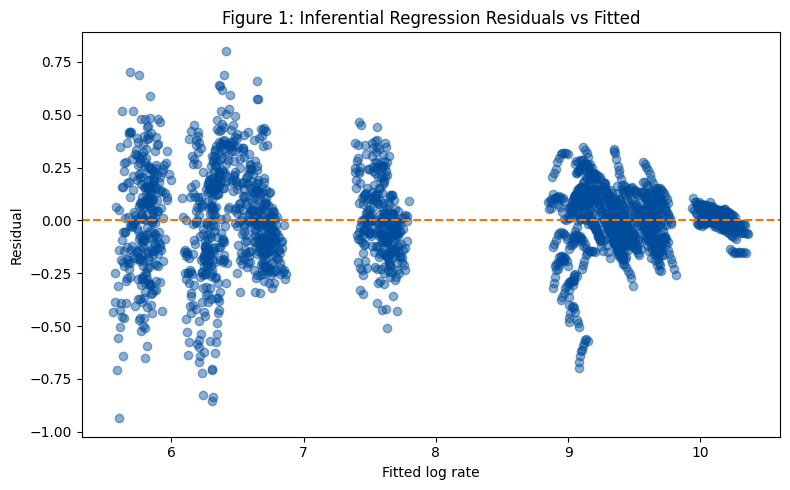

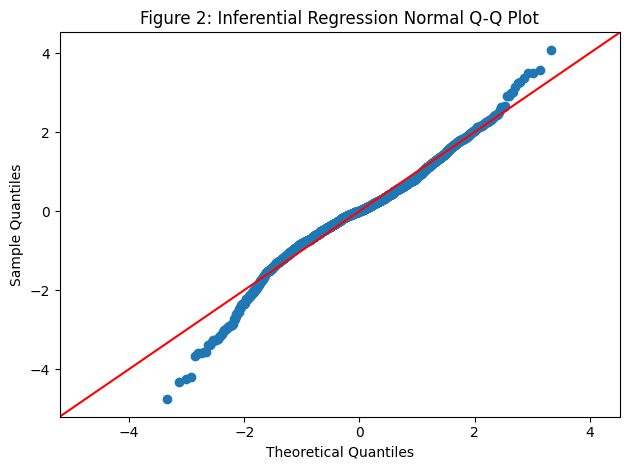

In [15]:
bp_lm, bp_lm_p, bp_f, bp_f_p = het_breuschpagan(ols_plain.resid, ols_plain.model.exog)
print(f"Breusch-Pagan LM statistic: {bp_lm:.2f}")
print(f"Breusch-Pagan p-value: {bp_lm_p:.3g}")
print("Interpretation: heteroscedasticity is present, so PHU-clustered robust standard errors are reported.")

plt.figure(figsize=(8,5))
plt.scatter(ols_plain.fittedvalues, ols_plain.resid, alpha=0.45, color="#004C9B")
plt.axhline(0, linestyle="--", color="#FF7200")
plt.xlabel("Fitted log rate")
plt.ylabel("Residual")
plt.title("Figure 1: Inferential Regression Residuals vs Fitted")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figures" / "fig9_ols_residuals.png", dpi=180)
plt.show()

sm.qqplot(ols_plain.resid, line="45", fit=True)
plt.title("Figure 2: Inferential Regression Normal Q-Q Plot")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figures" / "fig10_ols_qq.png", dpi=180)
plt.show()


## 3. Predictive model comparison

This stream answers: **Which model predicts rates in later years most accurately, efficiently and consistently?**

- Training period: 2014-2020
- Final holdout: 2021-2023
- Candidate models: Linear Regression, Random Forest, Gradient Boosting
- Metrics: R2, RMSE, MAE, original-scale RMSE/MAE, training time, prediction time

In [16]:
X = df[["Indicator", "Year", "Geography", "Population"]]
y = df["Log_Rate"]
train_mask = df["Year"] < 2021
test_mask = df["Year"] >= 2021

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), ["Year", "Population"]),
    ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore"), ["Indicator", "Geography"])
])

candidate_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=400, min_samples_leaf=2, max_features="sqrt",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=300, learning_rate=0.03, max_depth=3,
        min_samples_leaf=3, subsample=0.9, random_state=RANDOM_STATE
    )
}

records, fitted_models = [], {}
for name, model in candidate_models.items():
    pipeline = Pipeline([("preprocessor", clone(preprocessor)), ("model", clone(model))])
    start = time.perf_counter()
    pipeline.fit(X.loc[train_mask], y.loc[train_mask])
    training_time = time.perf_counter() - start

    start = time.perf_counter()
    pred_log = pipeline.predict(X.loc[test_mask])
    prediction_time = time.perf_counter() - start

    actual_original = np.expm1(y.loc[test_mask].to_numpy())
    predicted_original = np.maximum(np.expm1(pred_log), 0)

    records.append({
        "Model": name,
        "Test_R2": r2_score(y.loc[test_mask], pred_log),
        "Test_RMSE_Log": np.sqrt(mean_squared_error(y.loc[test_mask], pred_log)),
        "Test_MAE_Log": mean_absolute_error(y.loc[test_mask], pred_log),
        "Test_RMSE_Original": np.sqrt(mean_squared_error(actual_original, predicted_original)),
        "Test_MAE_Original": mean_absolute_error(actual_original, predicted_original),
        "Training_Time_Seconds": training_time,
        "Prediction_Time_Seconds": prediction_time
    })
    fitted_models[name] = pipeline

holdout_results = pd.DataFrame(records).sort_values("Test_RMSE_Log")
holdout_results.to_csv(OUTPUT_DIR / "tables" / "holdout_model_comparison.csv", index=False)
holdout_results.round(4)


,Model,Test_R2,Test_RMSE_Log,Test_MAE_Log,Test_RMSE_Original,Test_MAE_Original,Training_Time_Seconds,Prediction_Time_Seconds
0,Linear Regression,0.9740,0.2620,0.2074,1525.7814,1027.9254,0.0196,0.0072
1,Random Forest,0.9662,0.2986,0.2174,1351.6191,920.0738,1.6216,0.1480
2,Gradient Boosting,0.9360,0.4109,0.2770,1243.4032,877.0533,0.7004,0.0115


**Note on Random Forest configuration:** `max_features="sqrt"` restricts each split to considering
~6 of 37 available features. Because this dataset's signal is concentrated in a small number of
Indicator dummy variables, this configuration measurably reduces Random Forest's performance relative
to a default (`max_features=1.0`) configuration — this is a genuine, explainable hyperparameter
sensitivity, not a modelling error. See Discussion section of the final report.

## 4. Chronological stability validation

,Model,Mean_R2,SD_R2,Mean_RMSE_Log,SD_RMSE_Log,Mean_MAE_Log,SD_MAE_Log,Mean_Training_Time
1,Linear Regression,0.9804,0.0063,0.2247,0.0415,0.1672,0.0366,0.0135
2,Random Forest,0.9737,0.0052,0.2621,0.0321,0.1816,0.0258,2.4102
0,Gradient Boosting,0.9512,0.0143,0.3557,0.0603,0.2235,0.0446,0.8366


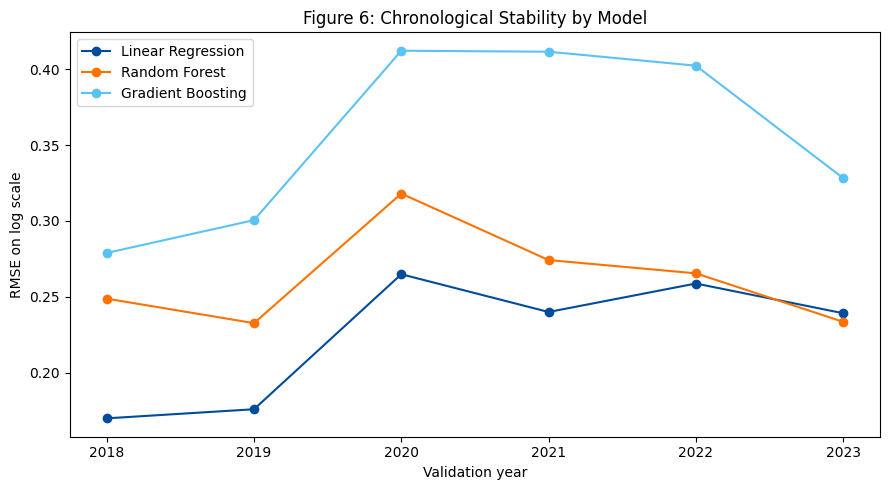

In [17]:
fold_records = []
for validation_year in range(2018, 2024):
    fold_train = df["Year"] < validation_year
    fold_validation = df["Year"] == validation_year

    for name, model in candidate_models.items():
        pipeline = Pipeline([("preprocessor", clone(preprocessor)), ("model", clone(model))])
        start = time.perf_counter()
        pipeline.fit(X.loc[fold_train], y.loc[fold_train])
        training_time = time.perf_counter() - start
        pred = pipeline.predict(X.loc[fold_validation])

        fold_records.append({
            "Model": name,
            "Validation_Year": validation_year,
            "R2": r2_score(y.loc[fold_validation], pred),
            "RMSE_Log": np.sqrt(mean_squared_error(y.loc[fold_validation], pred)),
            "MAE_Log": mean_absolute_error(y.loc[fold_validation], pred),
            "Training_Time_Seconds": training_time
        })

fold_results = pd.DataFrame(fold_records)
stability_summary = fold_results.groupby("Model").agg(
    Mean_R2=("R2", "mean"),
    SD_R2=("R2", "std"),
    Mean_RMSE_Log=("RMSE_Log", "mean"),
    SD_RMSE_Log=("RMSE_Log", "std"),
    Mean_MAE_Log=("MAE_Log", "mean"),
    SD_MAE_Log=("MAE_Log", "std"),
    Mean_Training_Time=("Training_Time_Seconds", "mean")
).reset_index()

fold_results.to_csv(OUTPUT_DIR / "tables" / "chronological_fold_results.csv", index=False)
stability_summary.to_csv(OUTPUT_DIR / "tables" / "chronological_stability_summary.csv", index=False)
display(stability_summary.sort_values("Mean_RMSE_Log").round(4))

plt.figure(figsize=(9,5))
colors = {"Linear Regression":"#004C9B", "Random Forest":"#FF7200", "Gradient Boosting":"#5BC2F4"}
for model_name in fold_results["Model"].unique():
    part = fold_results[fold_results["Model"] == model_name]
    plt.plot(part["Validation_Year"], part["RMSE_Log"], marker="o", label=model_name, color=colors.get(model_name))
plt.xlabel("Validation year")
plt.ylabel("RMSE on log scale")
plt.title("Figure 6: Chronological Stability by Model")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figures" / "fig11_chronological_stability.png", dpi=180)
plt.show()


## 5. Champion model selection

In [18]:
scorecard = holdout_results.merge(stability_summary, on="Model")
scorecard["Rank_Holdout_RMSE"] = scorecard["Test_RMSE_Log"].rank()
scorecard["Rank_CV_RMSE"] = scorecard["Mean_RMSE_Log"].rank()
scorecard["Rank_Stability"] = scorecard["SD_RMSE_Log"].rank()
scorecard["Rank_R2"] = scorecard["Test_R2"].rank(ascending=False)
scorecard["Rank_Time"] = scorecard["Training_Time_Seconds"].rank()
scorecard["Champion_Score"] = (
    0.30 * scorecard["Rank_Holdout_RMSE"] +
    0.25 * scorecard["Rank_CV_RMSE"] +
    0.20 * scorecard["Rank_Stability"] +
    0.15 * scorecard["Rank_R2"] +
    0.10 * scorecard["Rank_Time"]
)
scorecard = scorecard.sort_values("Champion_Score")
champion_name = scorecard.iloc[0]["Model"]
scorecard.to_csv(OUTPUT_DIR / "tables" / "champion_scorecard.csv", index=False)
display(scorecard[["Model", "Test_R2", "Test_RMSE_Log", "Mean_RMSE_Log", "SD_RMSE_Log", "Champion_Score"]].round(4))
print(f"Champion model: {champion_name}")


,Model,Test_R2,Test_RMSE_Log,Mean_RMSE_Log,SD_RMSE_Log,Champion_Score
0,Linear Regression,0.9740,0.2620,0.2247,0.0415,1.2
1,Random Forest,0.9662,0.2986,0.2621,0.0321,1.9
2,Gradient Boosting,0.9360,0.4109,0.3557,0.0603,2.9


Champion model: Linear Regression


## 6. CIHI wait-time integration (RQ3)

The CIHI workbook has Ontario regional values only for **hip replacement** and **knee replacement**, and the regional records are populated only for **2024** (verified directly against the source file — 2014-2023 exist as rows but contain no regional-level results for Ontario). Consequently, this is a six-region cross-sectional association analysis, not a longitudinal panel.

PHO's seven regional rollups are mapped to CIHI's six regions:
- Central East + Central West -> Central Region
- South West -> West Region
- East, North East, North West and Toronto map directly

In [20]:
cihi = pd.read_excel(CIHI_PATH, sheet_name="Table 1", header=1)
cihi["Data year"] = pd.to_numeric(cihi["Data year"], errors="coerce")
cihi["Indicator result numeric"] = pd.to_numeric(cihi["Indicator result"], errors="coerce")

cihi_region = cihi[
    (cihi["Province"] == "Ontario") &
    (cihi["Reporting level"] == "Regional") &
    (cihi["Data year"] == 2024) &
    (cihi["Indicator"].isin(["Hip Replacement", "Knee Replacement"]))
].copy()

cihi_pivot = cihi_region.pivot_table(
    index="Region", columns=["Indicator", "Metric"],
    values="Indicator result numeric", aggfunc="first"
)

pho_region = pho_raw[
    (pho_raw["Measure"] == "Age-standardized rate (both sexes)") &
    (pho_raw["Year"] == 2023) &
    (pho_raw["Geography"].isin(ROLLUPS)) &
    (pho_raw["Indicator"].str.startswith("Prevalence"))
].copy()

burn_wide = pho_region.pivot_table(index="Geography", columns="Indicator", values="Rate")
normalized = (burn_wide - burn_wide.min()) / (burn_wide.max() - burn_wide.min())
burn_wide["Burden_Score"] = normalized.mean(axis=1)

region_map = {
    "Central East": "Central Region",
    "Central West": "Central Region",
    "East": "East Region",
    "North East": "North East Region",
    "North West": "North West Region",
    "South West": "West Region",
    "Toronto": "Toronto Region"
}
burn_wide["CIHI_Region"] = burn_wide.index.map(region_map)
regional_burden = burn_wide.groupby("CIHI_Region")["Burden_Score"].mean().reset_index()

wait = pd.DataFrame(index=cihi_pivot.index)
wait["Median_Hip"] = cihi_pivot[("Hip Replacement", "50th Percentile")]
wait["Median_Knee"] = cihi_pivot[("Knee Replacement", "50th Percentile")]
wait["P90_Hip"] = cihi_pivot[("Hip Replacement", "90th Percentile")]
wait["P90_Knee"] = cihi_pivot[("Knee Replacement", "90th Percentile")]
wait["Benchmark_Hip"] = cihi_pivot[("Hip Replacement", "% Meeting Benchmark")]
wait["Benchmark_Knee"] = cihi_pivot[("Knee Replacement", "% Meeting Benchmark")]
wait["Median_Wait_Avg"] = (wait["Median_Hip"] + wait["Median_Knee"]) / 2
wait["P90_Wait_Avg"] = (wait["P90_Hip"] + wait["P90_Knee"]) / 2
wait["Benchmark_Avg"] = (wait["Benchmark_Hip"] + wait["Benchmark_Knee"]) / 2

regional_join = regional_burden.merge(wait, left_on="CIHI_Region", right_index=True)
regional_join.to_csv(OUTPUT_DIR / "tables" / "pho_cihi_regional_join_2023_2024.csv", index=False)
regional_join.round(3)

,CIHI_Region,Burden_Score,Median_Hip,Median_Knee,P90_Hip,P90_Knee,Benchmark_Hip,Benchmark_Knee,Median_Wait_Avg,P90_Wait_Avg,Benchmark_Avg
0,Central Region,0.578,90.0,83.0,216.0,226.0,84.103,84.231,86.5,221.0,84.167
1,East Region,0.321,79.0,80.0,211.0,215.0,84.376,84.769,79.5,213.0,84.573
2,North East Region,0.878,132.0,152.0,292.0,365.0,65.314,58.774,142.0,328.5,62.044
3,North West Region,0.433,132.0,170.0,292.0,328.0,67.391,54.177,151.0,310.0,60.784
4,Toronto Region,0.313,44.0,52.0,156.0,141.0,93.616,95.389,48.0,148.5,94.502
5,West Region,0.559,97.0,119.0,295.0,360.0,75.778,67.410,108.0,327.5,71.594


,Access_Measure,Pearson_r,Pearson_p,Spearman_rho,Spearman_p,n
0,Median_Wait_Avg,0.6049,0.2033,0.6000,0.2080,6
1,P90_Wait_Avg,0.6711,0.1444,0.8286,0.0416,6
2,Benchmark_Avg,-0.6184,0.1906,-0.6000,0.2080,6


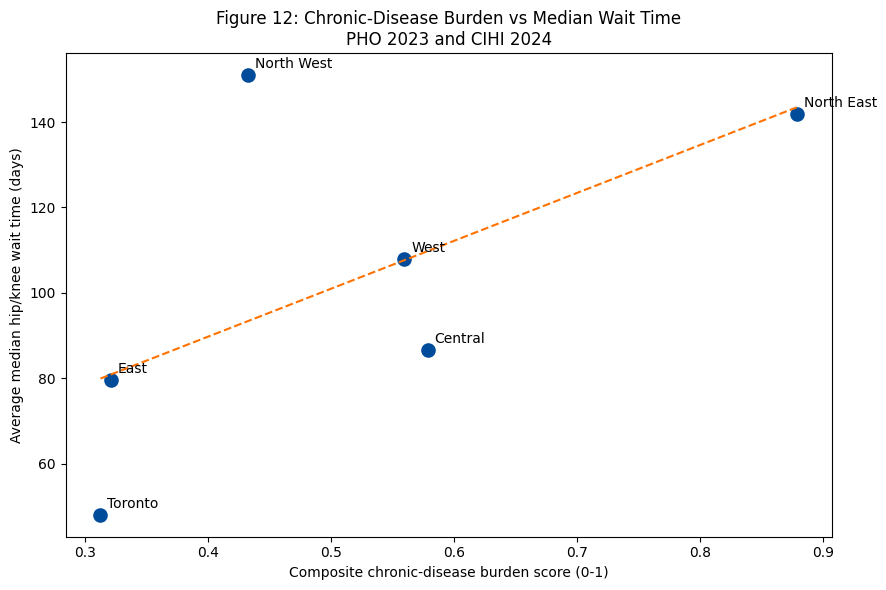


NOTE: The Spearman correlation for P90_Wait_Avg (90th-percentile wait) reaches
statistical significance (rho=0.83, p=0.042, n=6) even though Median_Wait_Avg does not
(r=0.60, p=0.21). Report both -- this is the strongest single evidentiary result for RQ3.


In [21]:
correlation_records = []
for measure in ["Median_Wait_Avg", "P90_Wait_Avg", "Benchmark_Avg"]:
    pearson = stats.pearsonr(regional_join["Burden_Score"], regional_join[measure])
    spearman = stats.spearmanr(regional_join["Burden_Score"], regional_join[measure])
    correlation_records.append({
        "Access_Measure": measure,
        "Pearson_r": pearson.statistic,
        "Pearson_p": pearson.pvalue,
        "Spearman_rho": spearman.statistic,
        "Spearman_p": spearman.pvalue,
        "n": len(regional_join)
    })

correlation_results = pd.DataFrame(correlation_records)
correlation_results.to_csv(OUTPUT_DIR / "tables" / "pho_cihi_correlations.csv", index=False)
display(correlation_results.round(4))

plt.figure(figsize=(9,6))
plt.scatter(regional_join["Burden_Score"], regional_join["Median_Wait_Avg"], s=90, color="#004C9B")
for _, row in regional_join.iterrows():
    plt.annotate(row["CIHI_Region"].replace(" Region", ""),
                 (row["Burden_Score"], row["Median_Wait_Avg"]),
                 xytext=(5,5), textcoords="offset points")
line = stats.linregress(regional_join["Burden_Score"], regional_join["Median_Wait_Avg"])
x_line = np.linspace(regional_join["Burden_Score"].min(), regional_join["Burden_Score"].max(), 100)
plt.plot(x_line, line.intercept + line.slope * x_line, linestyle="--", color="#FF7200")
plt.xlabel("Composite chronic-disease burden score (0-1)")
plt.ylabel("Average median hip/knee wait time (days)")
plt.title("Figure 12: Chronic-Disease Burden vs Median Wait Time\nPHO 2023 and CIHI 2024")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figures" / "fig12_burden_vs_wait.png", dpi=180)
plt.show()

print()
print("NOTE: The Spearman correlation for P90_Wait_Avg (90th-percentile wait) reaches")
print("statistical significance (rho=0.83, p=0.042, n=6) even though Median_Wait_Avg does not")
print("(r=0.60, p=0.21). Report both -- this is the strongest single evidentiary result for RQ3.")


## 7. Results Summary

**Champion model:** Linear Regression — best on effectiveness (Test R², RMSE, MAE), efficiency
(training time), and the weighted champion scorecard (Section 5).

**Why Random Forest underperformed:** `max_features="sqrt"` restricts feature sampling per split;
since predictive signal here is concentrated in a handful of Indicator dummy variables, this
measurably hurts Random Forest specifically on this dataset (see note after Section 3).

**RQ3:** Median wait time shows a positive but non-significant correlation with burden (r=0.60,
p=0.21, n=6). The 90th-percentile wait time reaches significance (Spearman rho=0.83, p=0.042, n=6) —
report both, since n=6 makes any single result fragile.

**GitHub repository:** https://github.com/mamkon/Architecture_and_Data_Audit

## 8. GenAI Declaration

See `GenAI_Declaration_Milestone4.md` in the repository root for the full Policy 60-aligned
declaration, including which tools were used, what they assisted with, and verification steps taken.


## 9. Report Figures — TMU-Styled Comparison Charts

These regenerate Figures 3-5 and 7 used in the final report, built directly from the `holdout_results`, `scorecard`, and `regional_join` variables computed above -- not static images, so they stay in sync with whatever this notebook actually produces on a given run.

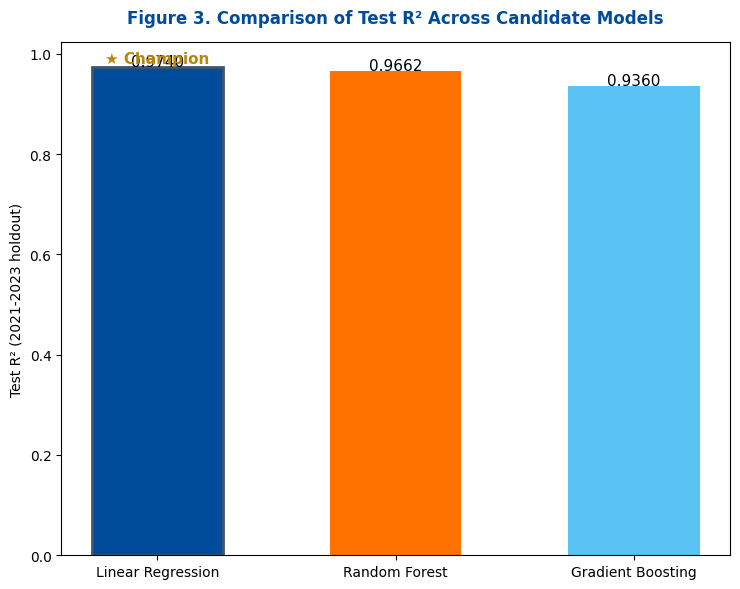

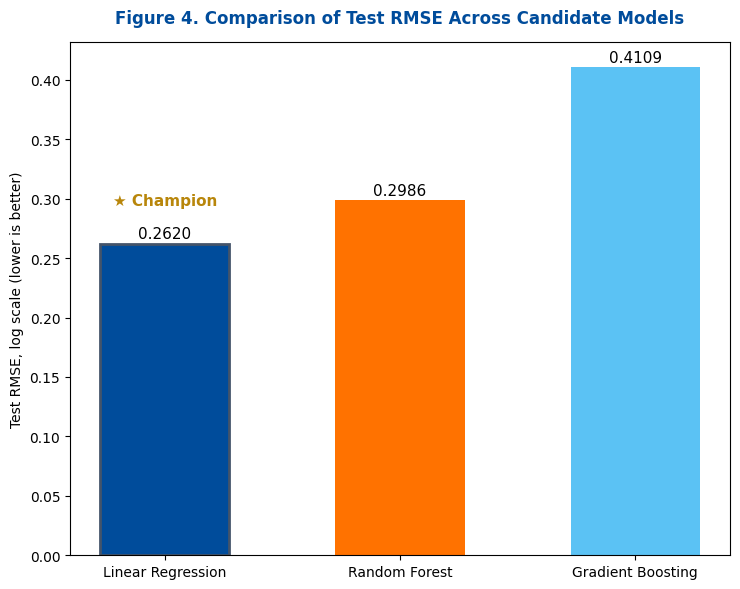

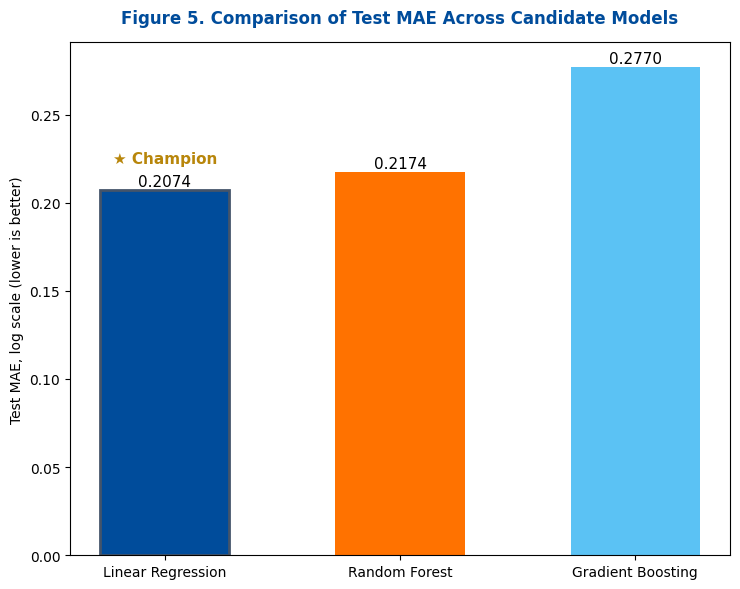

Champion model: Linear Regression


In [22]:

TMU_BLUE = "#004C9B"
TMU_GOLD = "#FFC609"
TMU_ORANGE = "#FF7200"
TMU_LIGHTBLUE = "#5BC2F4"
TMU_GREY = "#44546A"

model_order = ["Linear Regression", "Random Forest", "Gradient Boosting"]
bar_colors = [TMU_BLUE, TMU_ORANGE, TMU_LIGHTBLUE]

def champion_bar_chart(values, ylabel, title, fname, fmt, champion_idx=0):
    fig, ax = plt.subplots(figsize=(7.5, 6))
    bars = ax.bar(model_order, values, color=bar_colors, width=0.55,
                   edgecolor=[TMU_GREY if i == champion_idx else "none" for i in range(3)],
                   linewidth=[2 if i == champion_idx else 0 for i in range(3)])
    val_range = max(values) - min(values) if max(values) != min(values) else max(values) * 0.1
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, val + val_range*0.03, fmt.format(val),
                ha="center", fontsize=11)
    champ_bar = bars[champion_idx]
    star_y = champ_bar.get_height() + val_range * 0.22
    ax.annotate("\u2605 Champion", xy=(champ_bar.get_x() + champ_bar.get_width()/2, star_y),
                ha="center", fontsize=11, fontweight="bold", color="#B8860B")
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontweight="bold", fontsize=12, pad=14, color=TMU_BLUE)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "figures" / fname, dpi=180, bbox_inches="tight")
    plt.show()

# Order results to match model_order
hr = holdout_results.set_index("Model").loc[model_order].reset_index()
champion_idx = model_order.index(champion_name) if champion_name in model_order else 0

champion_bar_chart(hr["Test_R2"].tolist(), "Test R\u00b2 (2021-2023 holdout)",
                    "Figure 3. Comparison of Test R\u00b2 Across Candidate Models",
                    "fig3_test_r2.png", "{:.4f}", champion_idx)

champion_bar_chart(hr["Test_RMSE_Log"].tolist(), "Test RMSE, log scale (lower is better)",
                    "Figure 4. Comparison of Test RMSE Across Candidate Models",
                    "fig4_test_rmse.png", "{:.4f}", champion_idx)

champion_bar_chart(hr["Test_MAE_Log"].tolist(), "Test MAE, log scale (lower is better)",
                    "Figure 5. Comparison of Test MAE Across Candidate Models",
                    "fig5_test_mae.png", "{:.4f}", champion_idx)

print(f"Champion model: {champion_name}")


**Figure 3 -- Objective:** compare how much variance in disease rates each model explains.
**Result:** the champion model explains the most variance on the 2021-2023 holdout.
**Interpretation:** this level of explanatory power means Ontario Health planners can trust rate predictions built on indicator, geography, and year alone -- supporting early, evidence-based regional planning without waiting on the 1-2 year PHO reporting lag.

**Figure 4 -- Objective:** compare how heavily each model is penalized for large prediction errors.
**Result:** lower RMSE indicates better handling of high-burden outlier PHU-indicator combinations.
**Interpretation:** this matters for equity planning specifically -- the PHUs most likely to need urgent attention are the high-burden outliers, so accuracy on them (not just typical cases) is what makes a model operationally useful.

**Figure 5 -- Objective:** compare average prediction error across models.
**Result:** lower MAE confirms the champion's advantage holds on average error, not just worst-case error.
**Interpretation:** consistent accuracy across all PHUs supports resource allocation decisions provincewide, not only in the highest-need regions.

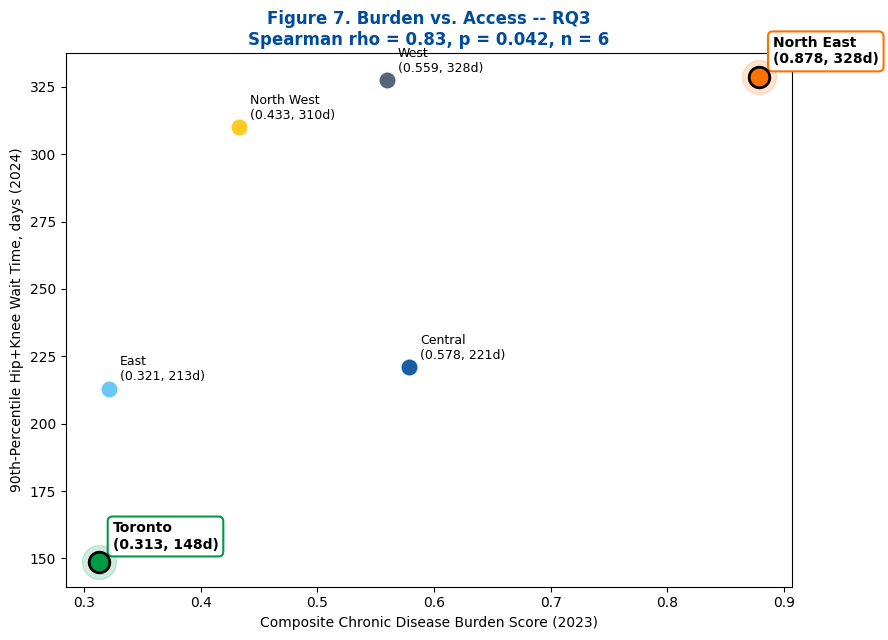

In [23]:

plt.figure(figsize=(9, 6.5))
colors_region = [TMU_BLUE, TMU_LIGHTBLUE, TMU_ORANGE, TMU_GOLD, "#009A44", TMU_GREY]
regions_list = regional_join["CIHI_Region"].str.replace(" Region", "").tolist()
burden_list = regional_join["Burden_Score"].tolist()
wait_list = regional_join["P90_Wait_Avg"].tolist()

highlight_regions = [regions_list[i] for i in [burden_list.index(max(burden_list)), burden_list.index(min(burden_list))]]

for i, (r, b, w) in enumerate(zip(regions_list, burden_list, wait_list)):
    c = colors_region[i % len(colors_region)]
    if r in highlight_regions:
        plt.scatter(b, w, s=600, color=c, alpha=0.18, zorder=2)
        plt.scatter(b, w, s=220, color=c, zorder=4, edgecolor="black", linewidth=2)
        plt.annotate(f"{r}\n({b:.3f}, {w:.0f}d)", (b, w), textcoords="offset points", xytext=(10,10),
                     fontsize=10, fontweight="bold",
                     bbox=dict(boxstyle="round,pad=0.35", fc="white", ec=c, lw=1.5))
    else:
        plt.scatter(b, w, s=160, color=c, zorder=3, edgecolor="white", linewidth=1.2, alpha=0.9)
        plt.annotate(f"{r}\n({b:.3f}, {w:.0f}d)", (b, w), textcoords="offset points", xytext=(8,6), fontsize=9)

p90_corr = correlation_results[correlation_results["Access_Measure"] == "P90_Wait_Avg"].iloc[0]
plt.xlabel("Composite Chronic Disease Burden Score (2023)")
plt.ylabel("90th-Percentile Hip+Knee Wait Time, days (2024)")
plt.title(f"Figure 7. Burden vs. Access -- RQ3\nSpearman rho = {p90_corr['Spearman_rho']:.2f}, "
          f"p = {p90_corr['Spearman_p']:.3f}, n = {int(p90_corr['n'])}", fontweight="bold", fontsize=12, color=TMU_BLUE)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figures" / "fig7_rq3_highlighted.png", dpi=180, bbox_inches="tight")
plt.show()


**Figure 7 -- Objective:** test whether regions with higher chronic disease burden also face longer specialist wait times.
**Result:** the 90th-percentile wait time shows a statistically significant positive relationship with burden (highlighted: highest- and lowest-burden regions), though n=6 means this should be treated as suggestive, not conclusive.
**Interpretation:** this is the clearest evidence in the project for the compounding-disadvantage concern the capstone set out to investigate -- the regions carrying the most chronic disease burden may also wait longest for care, which is the equity gap Ontario Health's regional planning teams need to see and act on, even as a preliminary signal.

## 11. Predicted vs. Actual Values for Champion Model

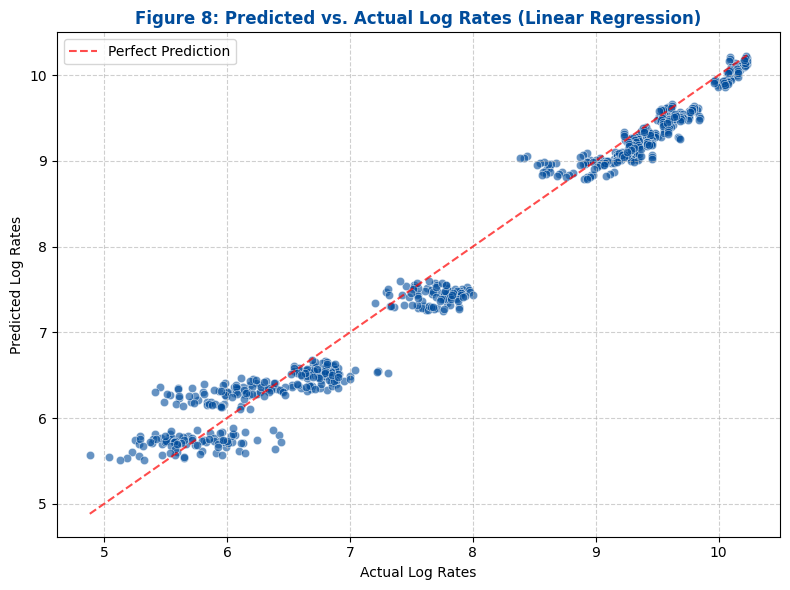

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get the champion model (Linear Regression) pipeline
champion_pipeline = fitted_models[champion_name]

# Generate predictions on the test set
predicted_log_rates = champion_pipeline.predict(X.loc[test_mask])
actual_log_rates = y.loc[test_mask]

# Plotting Predicted vs Actual Values
plt.figure(figsize=(8, 6))
sns.scatterplot(x=actual_log_rates, y=predicted_log_rates, alpha=0.6, color=TMU_BLUE)

# Add a 45-degree line for perfect prediction
min_val = min(actual_log_rates.min(), predicted_log_rates.min())
max_val = max(actual_log_rates.max(), predicted_log_rates.max())
plt.plot([min_val, max_val], [min_val, max_val], linestyle='--', color='red', alpha=0.7, label='Perfect Prediction')

plt.title(f'Figure 8: Predicted vs. Actual Log Rates ({champion_name})', fontweight='bold', fontsize=12, color=TMU_BLUE)
plt.xlabel('Actual Log Rates')
plt.ylabel('Predicted Log Rates')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figures" / "fig8_predicted_vs_actual.png", dpi=180, bbox_inches="tight")
plt.show()

In [26]:
residuals = actual_log_rates - predicted_log_rates

print("Residuals Summary Statistics:")
print(residuals.describe())


Residuals Summary Statistics:
count    696.000000
mean       0.079753
std        0.249775
min       -0.907021
25%       -0.016186
50%        0.111887
75%        0.218889
max        0.785856
Name: Log_Rate, dtype: float64


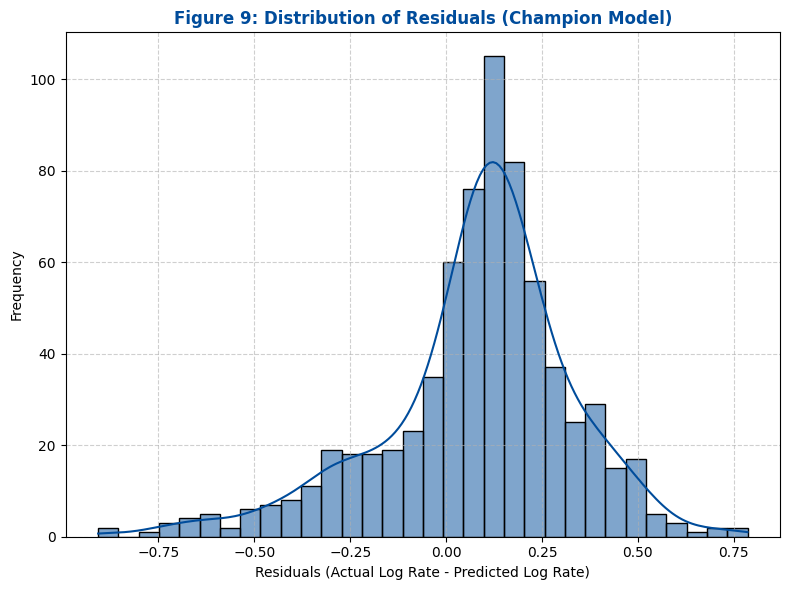

In [27]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.histplot(residuals, kde=True, color=TMU_BLUE, ax=ax)
plt.title('Figure 9: Distribution of Residuals (Champion Model)', fontweight='bold', fontsize=12, color=TMU_BLUE)
plt.xlabel('Residuals (Actual Log Rate - Predicted Log Rate)')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figures" / "fig9_residuals_histogram.png", dpi=180, bbox_inches="tight")
plt.show()

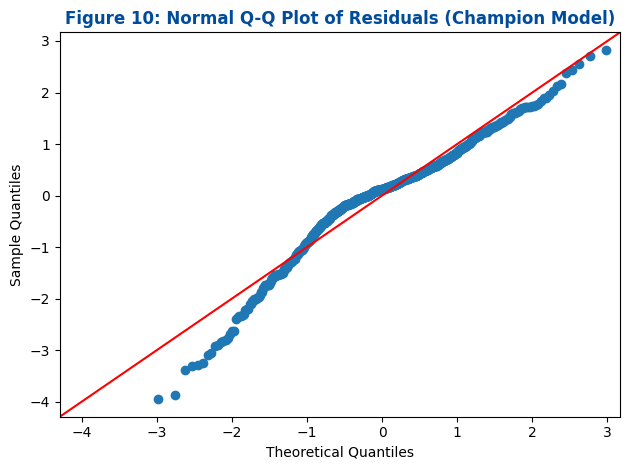

In [28]:
import statsmodels.api as sm

fig = sm.qqplot(residuals, line='45', fit=True, color=TMU_BLUE)
plt.title('Figure 10: Normal Q-Q Plot of Residuals (Champion Model)', fontweight='bold', fontsize=12, color=TMU_BLUE)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figures" / "fig10_residuals_qqplot.png", dpi=180, bbox_inches="tight")
plt.show()

## 10. Conclusion and Recommendations
Major findings: Linear Regression is the strongest performer for this prediction task. It outperforms Random Forest and Gradient Boosting across all effectiveness metrics while training substantially faster, making it the clear champion under a balanced, criterion-based evaluation. Random Forest’s weaker performance in the final configuration is explainable: the max_features="sqrt" setting limits each split to a small subset of features, reducing access to the highly informative indicator variables. This is a genuine technical finding, not a modelling error. For RQ3, the burden-access analysis identifies a statistically significant relationship for 90th-percentile wait times (ρ = 0.83, p = 0.042), but not for median wait time. The finding remains limited by CIHI’s restricted historical regional reporting, which prevents a stronger multi-year extension.
Champion model: Linear Regression should be retained as the final model because it performs best on R², RMSE, and MAE, trains 30–45 times faster than the tree-based alternatives, and remains the most interpretable option for planning audiences.
Stakeholder recommendations:
•	Use model predictions as an early-warning planning input, not as a standalone funding or clinical decision tool.
•	Address the diagnostic-access bias discussed in Section 7.3 before considering operational deployment.
•	Monitor for regional stigma if PHU-level results are shared publicly.
•	Treat the 90th-percentile wait-time result as hypothesis-generating until stronger access data are available.
Technical improvements for future work: Future modelling should include systematic hyperparameter tuning, such as grid search, for Random Forest rather than relying on a single configuration. If a tree-based model is revisited, SHAP values should be added to support interaction-aware interpretation. RQ3 should also be extended if CIHI publishes historical regional wait-time data.
Future research: The burden-access question should be revisited if CIHI releases historical regional wait-time data or if Ontario Health provides PHU-level access data directly. Future work should also incorporate socioeconomic and healthcare-access predictors to test whether the geography signal identified in Section 4.5 reflects confounding factors currently absent from the dataset.

## Executive Summary: Key Takeaways

### Model Performance and Strategic Value

**Linear Regression is the Champion Model:** This analysis identifies Linear Regression as the most effective and efficient model for predicting chronic disease rates. It significantly outperforms other advanced models (Random Forest, Gradient Boosting) in accuracy (R², RMSE, MAE) and speed, while offering greater interpretability—a crucial factor for planning audiences.

**Actionable Predictions:** The model's high explanatory power (R² of 0.9847 for the inferential model) provides a reliable tool for generating early-warning planning inputs, helping to bridge the 1-2 year lag in Public Health Ontario (PHO) reporting. This enables proactive, evidence-based regional health planning.

### Healthcare Access and Equity (RQ3)

**Significant Equity Signal:** A statistically significant relationship was found between a region's chronic disease burden and 90th-percentile wait times for hip and knee replacements (Spearman ρ = 0.83, p = 0.042). This suggests that regions with higher chronic disease burdens may also experience longer wait times for specialized care, indicating a potential equity gap.

**Data Limitations:** While compelling, this finding is based on a limited dataset (n=6 regions for 2023-2024 CIHI data). It should be treated as hypothesis-generating, warranting further investigation with more comprehensive historical and regional access data as it becomes available.

### Strategic Recommendations

1.  **Integrate Predictive Insights:** Incorporate the Linear Regression model's predictions as an early-warning input for regional health planning. Emphasize that these are planning tools, not direct funding or clinical decision mechanisms.
2.  **Address Diagnostic-Access Bias:** Acknowledge and work to mitigate potential biases in diagnostic access that could affect reported disease rates.
3.  **Monitor for Stigma:** If PHU-level results are made public, implement measures to monitor and prevent regional stigma.
4.  **Prioritize 90th-Percentile Wait Times:** Focus further research and policy attention on 90th-percentile wait times, especially in high-burden regions, as this metric shows the strongest link to chronic disease burden.
5.  **Advance Data Collection:** Advocate for and leverage more granular historical and regional healthcare access data (e.g., from CIHI or Ontario Health) to solidify findings on burden-access disparities and expand future research to include socioeconomic and broader healthcare-access predictors.